# 04 · Model training and validation results

**Goal:** show how the four models were trained, how they compare on the **validation** set, and what the results tell us. The training code lives in `src/train.py` (run once with `python -m src.train` from the project root); this notebook loads the saved models and explains and checks them.

| | |
|---|---|
| **Task** | regression: predict `target_ccme_value` (CCME water quality index, 0–100) |
| **Split** | by station: train 181,747 / validation 26,054 / test 51,973 rows (`split` column) |
| **Inputs** | 14 features: dissolved oxygen, pH, temperature, month (sin/cos), DO saturation, DO × temperature, the station's earlier readings, water type, country |
| **Metrics** | MAE, RMSE, R² |
| **Test set** | **not used here.** It is only used once, at the end, in `05_evaluation.ipynb` |
| **Before running** | `python -m src.train` must have been run (it creates `models/*.joblib` and `results/*.csv`) |

## 1. Setup

Imports and paths. `src.train` gives us the same metric function that the training script used.

In [1]:
import os, sys
sys.path.append("..")

import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt

from src.features import FEATURE_COLS, TARGET_COL, get_xy, load_final_dataset, make_features
from src.train import regression_metrics, DATA_PATH, MODEL_DIR, RESULT_DIR

FIG_DIR = str(RESULT_DIR / "figures")
os.makedirs(FIG_DIR, exist_ok=True)

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

## 2. Load the data and the saved models

Build the features and take the three splits with `get_xy`. We only print the test size, we do not use the test rows.

In [2]:
df = make_features(load_final_dataset(str(DATA_PATH)))
X_train, y_train, X_val, y_val, X_test, y_test = get_xy(df, split_col="split")

print(f"Target: {TARGET_COL}")
print(f"Train {len(X_train):,} | Validation {len(X_val):,} | Test {len(X_test):,} (test not used in this notebook)")
print(f"{len(FEATURE_COLS)} features:", FEATURE_COLS)

Target: target_ccme_value
Train 181,747 | Validation 26,054 | Test 51,973 (test not used in this notebook)
14 features: ['dissolved_oxygen_mg_l', 'ph', 'temperature_c', 'month_sin', 'month_cos', 'do_sat_pct', 'do_x_temp', 'dissolved_oxygen_mg_l_site_prev_mean', 'ph_site_prev_mean', 'temperature_c_site_prev_mean', 'site_prev_n', 'days_since_prev', 'waterbody_type', 'country']


Load the four saved models. Each one is a pipeline: preprocessing (median fill, scaling for Ridge, one-hot) fitted on the training rows, plus the model.

In [3]:
MODEL_FILES = {
    "Mean baseline": "dummy_regressor.joblib",
    "Ridge": "ridge_regression.joblib",
    "Random Forest": "random_forest.joblib",
    "XGBoost": "xgboost_regressor.joblib",
}
missing = [f for f in MODEL_FILES.values() if not (MODEL_DIR / f).exists()]
if missing:
    raise FileNotFoundError(f"Missing {missing}. Run `python -m src.train` from the project root first.")
models = {name: joblib.load(MODEL_DIR / f) for name, f in MODEL_FILES.items()}
print("Loaded:", list(models))

Loaded: ['Mean baseline', 'Ridge', 'Random Forest', 'XGBoost']


## 3. The four models and why

| Model | What it is | Why it is here |
|---|---|---|
| **Mean baseline** | always predicts the average training target | the floor: any real model must beat it (R² about 0) |
| **Ridge** | linear regression with an L2 penalty on the coefficients | simple, explainable, shows how much a straight-line model can do |
| **Random Forest** | many deep trees on random samples, predictions averaged | handles non-linear effects and interactions; averaging reduces variance |
| **XGBoost** | trees built one after another, each fixing the errors of the previous ones | usually the strongest on tabular data; the main model of the project |

## 4. Tuning: what was tried

Every setting was fitted on the **training** rows and scored on the **validation** rows; the setting with the lowest validation RMSE was kept (marked `True` in `selected`). The test set was never used. The tables are read from `results/tuning_results.csv`, which `python -m src.train` writes, so they always match the last training run. The grids change more than one setting at a time, so they show which *setting* did best, not the effect of a single knob.

In [4]:
tuning_path = RESULT_DIR / "tuning_results.csv"
if not tuning_path.exists():
    raise FileNotFoundError("Run `python -m src.train` first (it writes results/tuning_results.csv).")
tuning = pd.read_csv(tuning_path)
for name, g in tuning.groupby("model", sort=False):
    print(name)
    display(g.drop(columns="model").round(4).reset_index(drop=True))

DummyRegressor


,parameters,mae,rmse,r2,selected
0,"{""strategy"": ""mean""}",9.7617,13.912,-0.0054,True


Ridge


,parameters,mae,rmse,r2,selected
0,"{""alpha"": 0.001}",8.6875,12.2626,0.2188,True
1,"{""alpha"": 0.01}",8.6875,12.2626,0.2188,False
2,"{""alpha"": 0.1}",8.6875,12.2626,0.2188,False
3,"{""alpha"": 1}",8.6875,12.2626,0.2188,False
4,"{""alpha"": 10}",8.6875,12.2627,0.2188,False
5,"{""alpha"": 100}",8.6876,12.2634,0.2187,False
6,"{""alpha"": 1000}",8.6894,12.2714,0.2177,False


RandomForestRegressor


,parameters,mae,rmse,r2,selected
0,"{""max_depth"": 6, ""min_samples_leaf"": 5, ""n_est...",8.1624,11.8543,0.2700,False
1,"{""max_depth"": 8, ""min_samples_leaf"": 5, ""n_est...",7.9854,11.5885,0.3024,False
2,"{""max_depth"": 10, ""min_samples_leaf"": 5, ""n_es...",7.8622,11.3906,0.3260,False
3,"{""max_depth"": 12, ""min_samples_leaf"": 5, ""n_es...",7.7876,11.2811,0.3389,False
4,"{""max_depth"": 16, ""min_samples_leaf"": 5, ""n_es...",7.7728,11.2470,0.3429,True
5,"{""max_depth"": 10, ""min_samples_leaf"": 2, ""n_es...",7.8622,11.3886,0.3262,False
6,"{""max_depth"": 10, ""min_samples_leaf"": 10, ""n_e...",7.8649,11.3947,0.3255,False
7,"{""max_depth"": 10, ""min_samples_leaf"": 20, ""n_e...",7.8699,11.4032,0.3245,False


XGBRegressor


,parameters,mae,rmse,r2,selected
0,"{""learning_rate"": 0.05, ""max_depth"": 4, ""n_est...",7.8603,11.4032,0.3245,False
1,"{""learning_rate"": 0.05, ""max_depth"": 6, ""n_est...",7.7733,11.2581,0.3416,False
2,"{""learning_rate"": 0.05, ""max_depth"": 8, ""n_est...",7.7338,11.2289,0.3450,False
3,"{""learning_rate"": 0.05, ""max_depth"": 10, ""n_es...",7.8056,11.2815,0.3388,False
4,"{""learning_rate"": 0.03, ""max_depth"": 8, ""n_est...",7.7292,11.2048,0.3478,True
5,"{""learning_rate"": 0.1, ""max_depth"": 8, ""n_esti...",7.8844,11.3644,0.3291,False
6,"{""learning_rate"": 0.05, ""max_depth"": 8, ""n_est...",7.8015,11.2966,0.3371,False


**What we see → What we do about it:** *(write after running `python -m src.train`; look at the tables above and answer these)*
- Does Ridge change with alpha? If the scores are identical, the linear model has nothing to shrink and its tuning has no effect.
- For Random Forest and XGBoost, is the best setting **inside** the range tried, or at an edge? An edge means the grid should be extended.
- How big is the spread between the best and worst tree setting? A small spread means the limit is the information in the inputs, not the settings.

## 5. Validation results
Score every saved model on the training rows and on the validation rows. The model has seen the training rows, not the validation rows (validation stations are unseen). **Caution:** the settings were chosen on these same validation rows, so these scores are slightly optimistic. The unbiased estimate comes from the test set in `05_evaluation.ipynb`.

In [5]:
rows, val_pred = [], {}
for name, model in models.items():
    p_tr = model.predict(X_train)
    p_va = model.predict(X_val)
    val_pred[name] = p_va
    m_tr, m_va = regression_metrics(y_train, p_tr), regression_metrics(y_val, p_va)
    rows.append({"model": name, "val MAE": m_va["mae"], "val RMSE": m_va["rmse"], "val R2": m_va["r2"],
                 "train R2": m_tr["r2"], "R2 gap (train - val)": m_tr["r2"] - m_va["r2"]})
results = pd.DataFrame(rows).set_index("model").sort_values("val RMSE")
display(results.round(4))

name_map = {"DummyRegressor": "Mean baseline", "Ridge": "Ridge",
            "RandomForestRegressor": "Random Forest", "XGBRegressor": "XGBoost"}
saved = pd.read_csv(RESULT_DIR / "validation_metrics.csv")
saved["model"] = saved["model"].map(name_map)
saved = saved.set_index("model")
assert set(saved.index) == set(results.index), "model names in validation_metrics.csv do not match the saved models"
diff = (saved.loc[results.index, "rmse"] - results["val RMSE"]).abs().max()
print("Largest difference to results/validation_metrics.csv (RMSE):", round(float(diff), 6))
best_name = results.index[0]
print("Best model on validation:", best_name)

,val MAE,val RMSE,val R2,train R2,R2 gap (train - val)
model,,,,,
XGBoost,7.7292,11.2048,0.3478,0.4607,0.1129
Random Forest,7.7728,11.2470,0.3429,0.5575,0.2147
Ridge,8.6875,12.2626,0.2188,0.2110,-0.0078
Mean baseline,9.7617,13.9120,-0.0054,0.0000,0.0054


Largest difference to results/validation_metrics.csv (RMSE): 0.0
Best model on validation: XGBoost


**What we see → What we do about it:** *(Vaishnavi/Anusha: write 2 sentences: which model is best, by how much it beats the baseline, and what R² around 0.34 means.)*

### 5.1 Comparison chart
Validation error (lower is better) and R² (higher is better) for the four models.

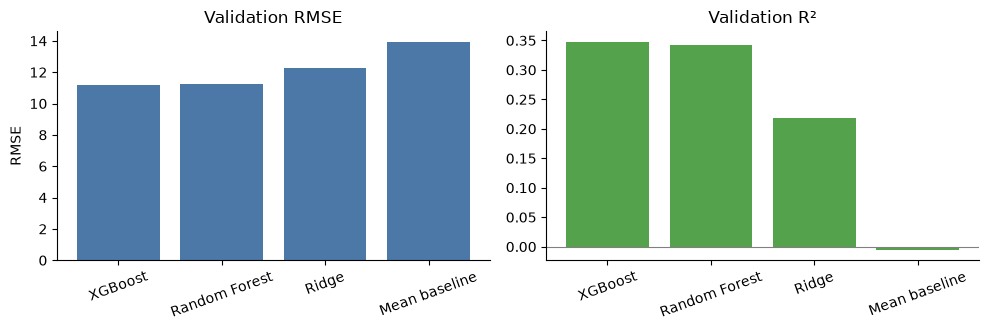

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
order = results.index
axes[0].bar(order, results["val RMSE"], color="#4c78a8"); axes[0].set_title("Validation RMSE"); axes[0].set_ylabel("RMSE")
axes[1].bar(order, results["val R2"], color="#54a24b"); axes[1].set_title("Validation R²"); axes[1].axhline(0, color="grey", lw=0.8)
for ax in axes: ax.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/models_val_comparison.png", bbox_inches="tight"); plt.show()

## 6. Overfitting check
Train R² against validation R². A big gap means the model memorised the training stations instead of learning a general rule.

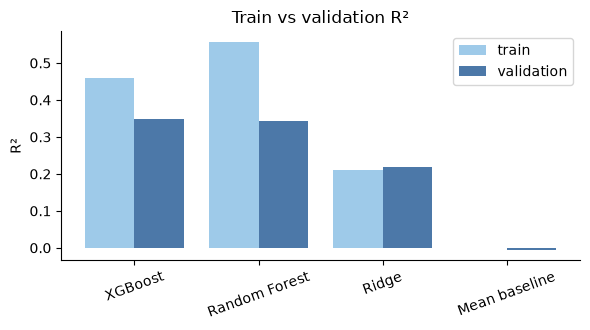

In [7]:
fig, ax = plt.subplots(figsize=(6, 3.4))
x = np.arange(len(results))
ax.bar(x - 0.2, results["train R2"], 0.4, label="train", color="#9ecae9")
ax.bar(x + 0.2, results["val R2"], 0.4, label="validation", color="#4c78a8")
ax.set_xticks(x); ax.set_xticklabels(results.index, rotation=20); ax.set_ylabel("R²"); ax.legend()
ax.set_title("Train vs validation R²")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/models_overfitting.png", bbox_inches="tight"); plt.show()

**What we see → What we do about it:** *(write: which model has the largest gap, what this means for bias and variance, and what we would try, e.g. shallower trees or a bigger minimum leaf.)*

## 7. Predicted vs actual (best model, validation)
A perfect model puts every point on the diagonal. The target is capped at 100, and 44% of rows sit exactly at 100, so the cloud is squeezed at the top.

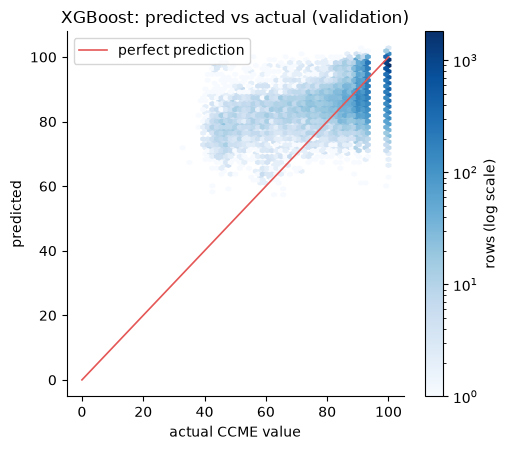

In [8]:
pred = val_pred[best_name]
fig, ax = plt.subplots(figsize=(5.2, 4.6))
hb = ax.hexbin(y_val, pred, gridsize=45, bins="log", cmap="Blues", mincnt=1)
ax.plot([0, 100], [0, 100], color="#e45756", lw=1.2, label="perfect prediction")
ax.set_xlabel("actual CCME value"); ax.set_ylabel("predicted"); ax.set_title(f"{best_name}: predicted vs actual (validation)")
ax.legend(loc="upper left"); fig.colorbar(hb, label="rows (log scale)")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/models_pred_vs_actual.png", bbox_inches="tight"); plt.show()

**What we see → What we do about it:** *(write: does the model under-predict high values and over-predict low ones? Why does the cap at 100 make that happen?)*

## 8. Error by country (best model, validation)
A quick look at where the model is better or worse. Ireland is 82% at 100, so it is easy; the full error analysis is in `05_evaluation.ipynb`.

In [9]:
err = pd.DataFrame({"country": df.loc[X_val.index, "country"],
                    "model abs error": np.abs(y_val.to_numpy() - val_pred[best_name]),
                    "baseline abs error": np.abs(y_val.to_numpy() - val_pred["Mean baseline"])})
by_country = err.groupby("country").agg(rows=("model abs error", "size"), model_MAE=("model abs error", "mean"),
                                        baseline_MAE=("baseline abs error", "mean")).round(2)
display(by_country)

,rows,model_MAE,baseline_MAE
country,,,
Canada,314,7.10,7.26
England,19396,9.18,10.18
Ireland,5986,3.37,8.59
USA,358,2.24,8.74


**What we see → What we do about it:** *(write: in which country does the model help most over the baseline, and where does it barely help?)*

## 9. Which features does the model use?
Importance of each input for the Random Forest and XGBoost. This is a sanity check (no forbidden column should appear) and a first look at what drives the predictions. It shows association, not cause; SHAP in `05_evaluation.ipynb` gives a more careful view.

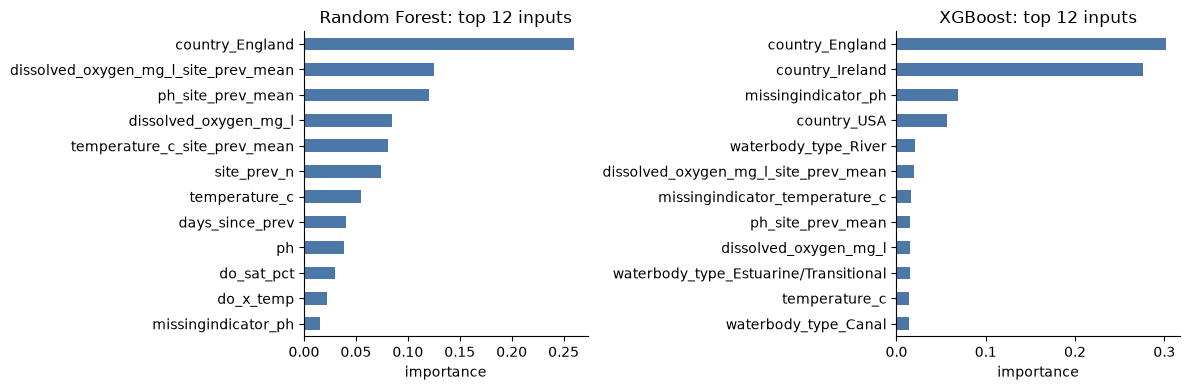

In [10]:
def top_importances(pipe, n=12):
    names = pipe.named_steps["preprocessor"].get_feature_names_out()
    names = [s.replace("num__", "").replace("cat__", "") for s in names]
    imp = pd.Series(pipe.named_steps["model"].feature_importances_, index=names)
    return imp.sort_values(ascending=False).head(n)[::-1]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, name in zip(axes, ["Random Forest", "XGBoost"]):
    top_importances(models[name]).plot.barh(ax=ax, color="#4c78a8")
    ax.set_title(f"{name}: top 12 inputs"); ax.set_xlabel("importance")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/models_feature_importance.png", bbox_inches="tight"); plt.show()

**What we see → What we do about it:** *(write: which inputs matter most, and does the station history (`*_site_prev_mean`) or the country dominate?)*

## 10. Limitations and next steps

- **Moderate score.** Validation R² is about 0.34. The five parameters that the target is calculated from are held out on purpose (leakage), so the remaining inputs explain only part of it.
- **Limited tuning.** Each grid changes one setting at a time, but only a few values of each were tried; check whether the winners sit at an edge of the grid.
- **One validation set.** Settings were chosen on one validation split, not with cross-validation, so the validation scores are slightly optimistic.
- **Bounded target.** The index is capped at 0–100 and 44% of rows are exactly 100; a regression model does not know the cap.
- **Test set untouched.** Final test scores, confidence intervals, error analysis and SHAP are produced in `05_evaluation.ipynb`.